## 3. Лабораторная работа №2

### 3.1. Цель лабораторной работы

В лабораторной работе реализуются повороты и отражения на плоскости с помощью матриц и комплексных чисел.

## 3.2. Задание №1
1. Нарисуйте неправильный многоугольник (не треугольник, не квадрат) задав коорди
наты его вершин массивом NumPy.
2. С помощью матрицы для двумерных вращений
𝑅(𝜃) = (cos 𝜃
− sin 𝜃
sin 𝜃
cos 𝜃 )
поверните данный многоугольник на любой произвольный угол вокруг начала ко
ординат.

3. Создайте ползунок, который будет вращать ваш многоугольник против часовой стрелки
с шагом 1°
.

4. Реализуйте теперь поворот многоугольника вокруг произвольной точки на плоскости.
Точку, вокруг которой делается поворот нужно отобразить на рисунке.

5. Чтобы проверить корректность программы следует убедиться, что вершины много
угольника описывают круговые траектории при их движении. Для этого постройте
несколько вспомогательных окружностей или дуг окружностей. Центры окружностей
должны лежать в точке, относительно которой осуществляется вращение, а радиусы
должны быть равны расстоянию от центра до соответствующей вершины многоуголь
ника. Если все сделано правильно, то будет видно, как многоугольник при вращении
скользит своими вершинами по построенным окружностям. Как рисовать дуги окруж
ности см. Раздел 3.5

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider, IntSlider

polygon = np.array([
    [1, 2],
    [3, 4],
    [5, 3],
    [4, 1],
    [2, 0]
])

def rotate_polygon(points, theta_deg):
    theta = np.radians(theta_deg)
    R = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)]
    ])
    return points @ R.T

def rotate_around_point(points, center, theta_deg):
    shifted = points - center
    rotated = rotate_polygon(shifted, theta_deg)
    return rotated + center

def plot_rotated_polygon(theta=0, cx=3.0, cy=2.0):
    center = np.array([cx, cy])
    rotated = rotate_around_point(polygon, center, theta)
    
    plt.figure(figsize=(6,6))
    plt.plot(*np.vstack([polygon, polygon[0]]).T, 'bo-', label='Исходный')
    plt.plot(*np.vstack([rotated, rotated[0]]).T, 'ro-', label='Повернутый')
    plt.plot(center[0], center[1], 'ks', label='Центр вращения')
    for vertex in polygon:
        radius = np.linalg.norm(vertex - center)
        circle = plt.Circle(center, radius, color='gray', fill=False, linestyle='--')
        plt.gca().add_patch(circle)
    plt.legend()
    plt.axis('equal')
    plt.xlim(-1, 7)
    plt.ylim(-1, 7)
    plt.grid(True)
    plt.show()

interact(
    plot_rotated_polygon,
    theta=IntSlider(value=0, min=0, max=360, step=1, description='Угол (°)'),
    cx=FloatSlider(value=3.0, min=-1.0, max=7.0, step=0.1, description='Центр X'),
    cy=FloatSlider(value=2.0, min=-1.0, max=7.0, step=0.1, description='Центр Y')
)

interactive(children=(IntSlider(value=0, description='Угол (°)', max=360), FloatSlider(value=3.0, description=…

<function __main__.plot_rotated_polygon(theta=0, cx=3.0, cy=2.0)>

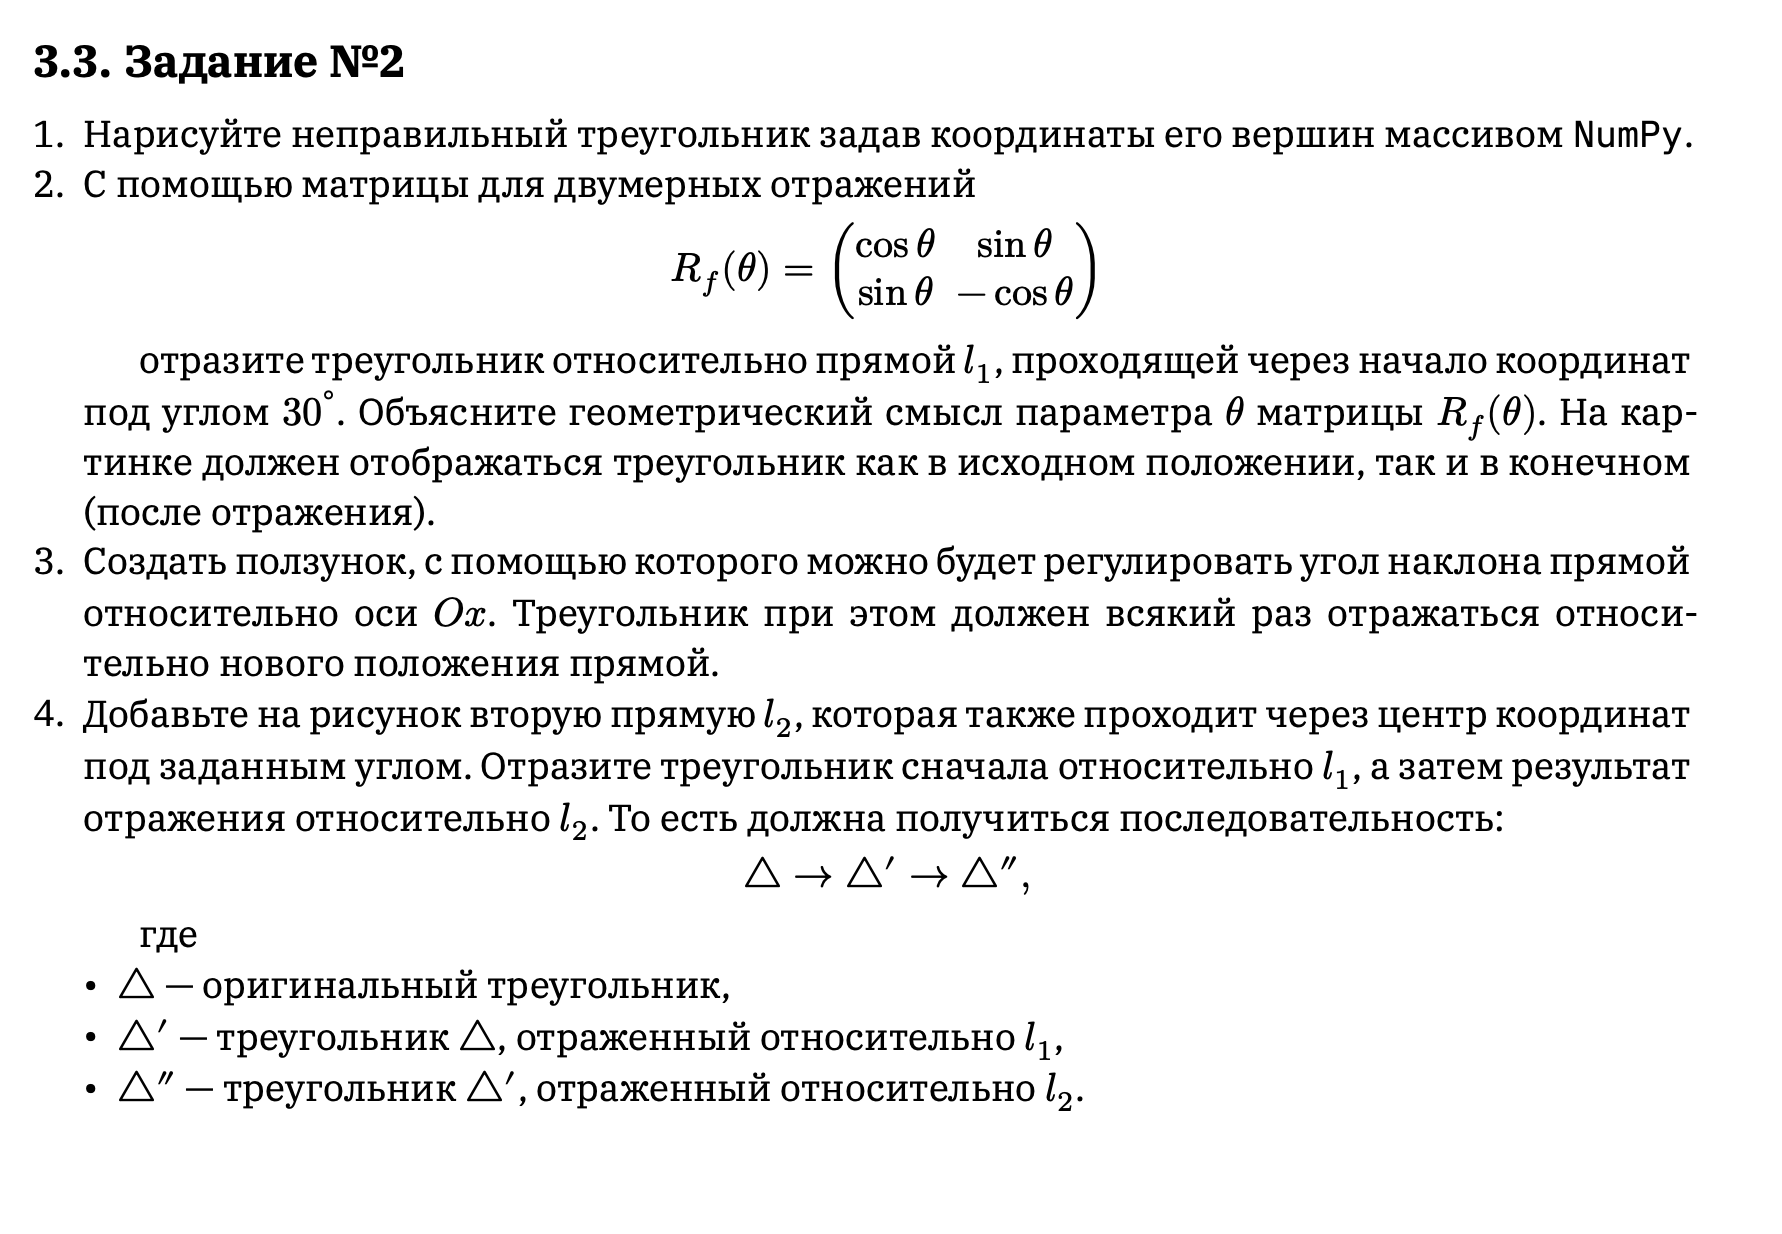

In [7]:
# 1. Задаём неправильный треугольник
triangle = np.array([
    [1, 2],
    [4, 1],
    [2, 4]
])

# 2. Функция для матрицы отражения относительно прямой, проходящей через начало координат под углом theta
def reflection_matrix(theta_deg):
    theta = np.radians(theta_deg)
    return np.array([
        [ np.cos(theta),  np.sin(theta)],
        [ np.sin(theta), -np.cos(theta)]
    ])

# 3. Функция для отражения треугольника относительно прямой под углом theta
def reflect_triangle(tri, theta_deg):
    Rf = reflection_matrix(theta_deg)
    return tri @ Rf.T

# 4. Визуализация
def plot_reflections(theta1=30.0, theta2=60.0):
    # Исходный треугольник
    tri = triangle
    # Отражение относительно l1
    tri_ref1 = reflect_triangle(tri, theta1)
    # Отражение относительно l2 (после l1)
    tri_ref2 = reflect_triangle(tri_ref1, theta2)
    
    fig, ax = plt.subplots(figsize=(7,7))
    # Оригинальный треугольник
    ax.plot(*np.vstack([tri, tri[0]]).T, 'bo-', label='△ (оригинал)')
    # Отражённый относительно l1
    ax.plot(*np.vstack([tri_ref1, tri_ref1[0]]).T, 'ro-', label="△' (отражение l₁)")
    # Отражённый относительно l2
    ax.plot(*np.vstack([tri_ref2, tri_ref2[0]]).T, 'go-', label="△'' (отражение l₂)")
    
    # Подписи вершин
    for i, (x, y) in enumerate(tri):
        ax.text(x, y, f'  P{i+1}', color='blue', fontsize=12)
    for i, (x, y) in enumerate(tri_ref1):
        ax.text(x, y, f"  P'{i+1}", color='red', fontsize=12)
    for i, (x, y) in enumerate(tri_ref2):
        ax.text(x, y, f"  P''{i+1}", color='green', fontsize=12)
    
    # Прямая l1
    l1_angle = np.radians(theta1)
    l1_x = np.array([-5, 5])
    l1_y = np.tan(l1_angle) * l1_x
    ax.plot(l1_x, l1_y, 'k--', label=f'l₁ (угол {theta1:.1f}°)')
    
    # Прямая l2
    l2_angle = np.radians(theta2)
    l2_x = np.array([-5, 5])
    l2_y = np.tan(l2_angle) * l2_x
    ax.plot(l2_x, l2_y, 'm-.', label=f'l₂ (угол {theta2:.1f}°)')
    
    ax.set_xlim(-5, 7)
    ax.set_ylim(-5, 7)
    ax.set_aspect('equal')
    ax.legend()
    ax.grid(True)
    plt.title("Отражение треугольника относительно двух прямых")
    plt.show()
    
    # 5. Геометрический смысл θ:
    print(f"Геометрический смысл θ: угол между осью Ox и прямой отражения.\n"
          f"Треугольник сначала отражается относительно l₁ (угол {theta1:.1f}°), затем результат относительно l₂ (угол {theta2:.1f}°).")

# 6. Интерактивные ползунки для углов прямых l1 и l2
interact(
    plot_reflections,
    theta1=FloatSlider(value=30.0, min=0.0, max=180.0, step=1.0, description='Угол l₁ (°)'),
    theta2=FloatSlider(value=60.0, min=0.0, max=180.0, step=1.0, description='Угол l₂ (°)')
)

interactive(children=(FloatSlider(value=30.0, description='Угол l₁ (°)', max=180.0, step=1.0), FloatSlider(val…

<function __main__.plot_reflections(theta1=30.0, theta2=60.0)>

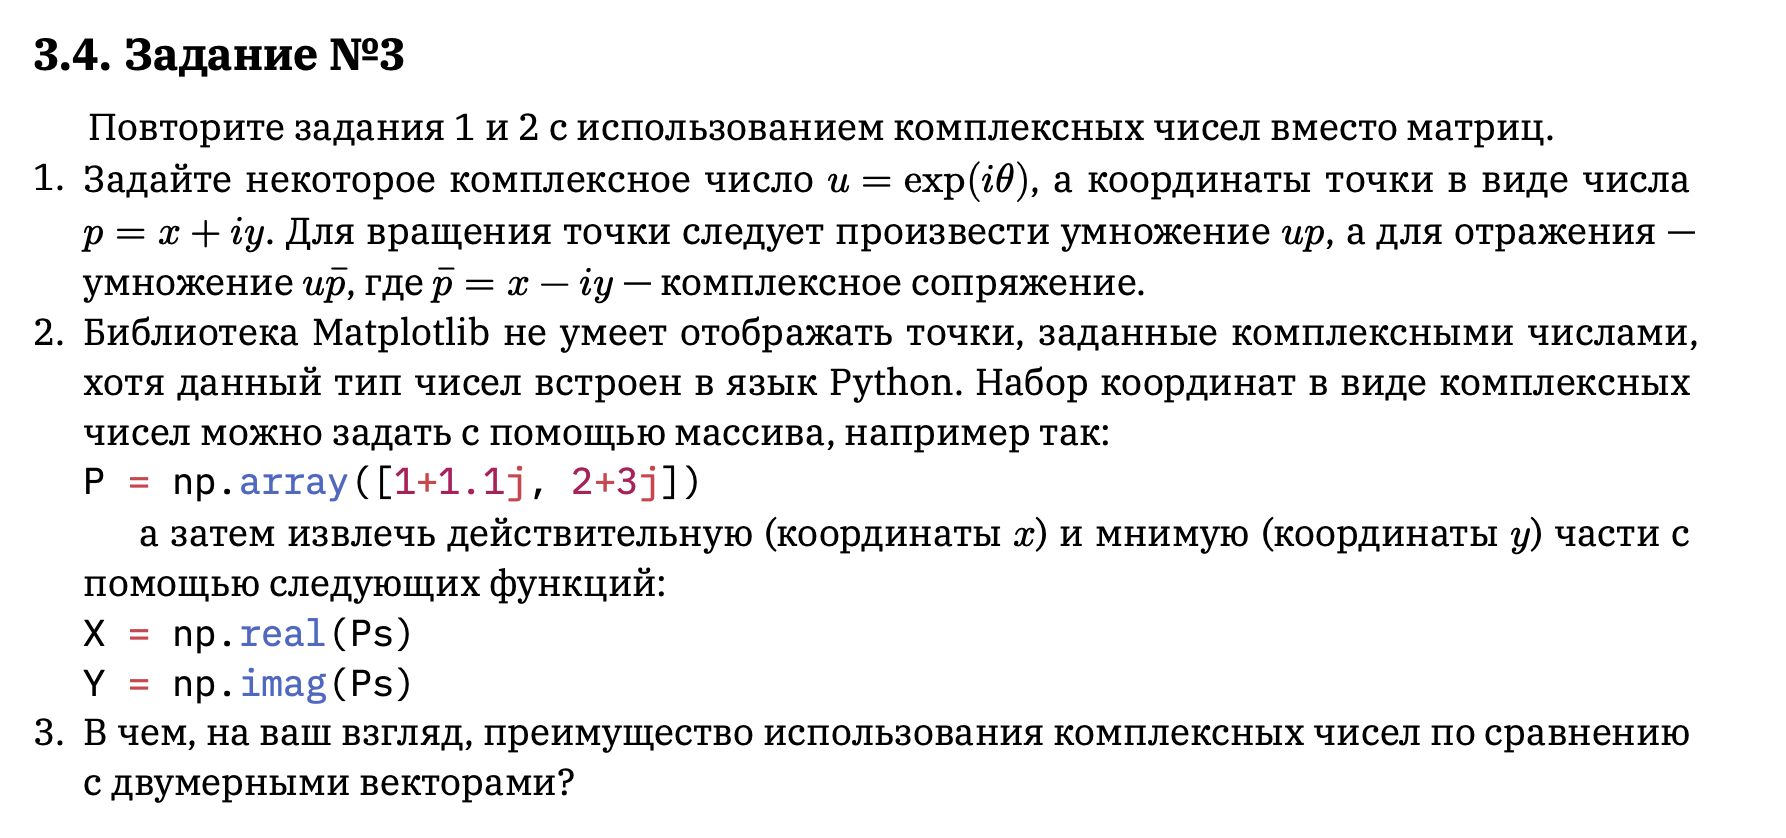

In [8]:
# 1. Задаём неправильный многоугольник (например, пятиугольник) в виде массива комплексных чисел
polygon = np.array([
    1 + 2j,
    3 + 4j,
    5 + 3j,
    4 + 1j,
    2 + 0j
])

# Функция для вращения многоугольника вокруг начала координат с помощью комплексного числа u = exp(i*theta)
def rotate_complex(P, theta_deg):
    theta_rad = np.radians(theta_deg)
    u = np.exp(1j * theta_rad)
    return u * P

# Функция для вращения вокруг произвольной точки (сначала переносим в начало координат, вращаем, возвращаем обратно)
def rotate_complex_around_point(P, center, theta_deg):
    return rotate_complex(P - center, theta_deg) + center

# Функция для отражения относительно прямой через начало координат под углом theta
def reflect_complex(P, theta_deg):
    theta_rad = np.radians(theta_deg)
    u = np.exp(1j * theta_rad)
    return np.conj(u * P)

# Функция для отражения относительно произвольной прямой (через точку center)
def reflect_complex_around_point(P, center, theta_deg):
    return reflect_complex(P - center, theta_deg) + center

# Визуализация вращения и отражения
def plot_complex(theta=0.0, phi=30.0, cx=3.0, cy=2.0):
    center = cx + 1j * cy
    # Вращение вокруг центра
    rotated = rotate_complex_around_point(polygon, center, theta)
    # Отражение относительно прямой через центр под углом phi
    reflected = reflect_complex_around_point(polygon, center, phi)
    
    plt.figure(figsize=(7,7))
    # Исходный многоугольник
    plt.plot(np.real(np.append(polygon, polygon[0])), np.imag(np.append(polygon, polygon[0])), 'bo-', label='Исходный')
    # Повернутый
    plt.plot(np.real(np.append(rotated, rotated[0])), np.imag(np.append(rotated, rotated[0])), 'ro-', label='Повернутый')
    # Отражённый
    plt.plot(np.real(np.append(reflected, reflected[0])), np.imag(np.append(reflected, reflected[0])), 'go-', label='Отражённый')
    # Центр вращения/отражения
    plt.plot(np.real(center), np.imag(center), 'ks', label='Центр')
    # Прямая отражения
    t = np.linspace(-10, 10, 2)
    phi_rad = np.radians(phi)
    line = center + t * np.exp(1j * phi_rad)
    plt.plot(np.real(line), np.imag(line), 'k--', label=f'Прямая отражения (угол {phi:.1f}°)')
    plt.axis('equal')
    plt.xlim(-2, 8)
    plt.ylim(-2, 8)
    plt.legend()
    plt.grid(True)
    plt.title("Вращение и отражение многоугольника (через комплексные числа)")
    plt.show()

# Интерактивные ползунки
interact(
    plot_complex,
    theta=FloatSlider(value=0.0, min=0.0, max=360.0, step=1.0, description='Угол вращения (°)'),
    phi=FloatSlider(value=30.0, min=0.0, max=180.0, step=1.0, description='Угол отражения (°)'),
    cx=FloatSlider(value=3.0, min=-2.0, max=8.0, step=0.1, description='Центр X'),
    cy=FloatSlider(value=2.0, min=-2.0, max=8.0, step=0.1, description='Центр Y')
)

interactive(children=(FloatSlider(value=0.0, description='Угол вращения (°)', max=360.0, step=1.0), FloatSlide…

<function __main__.plot_complex(theta=0.0, phi=30.0, cx=3.0, cy=2.0)>

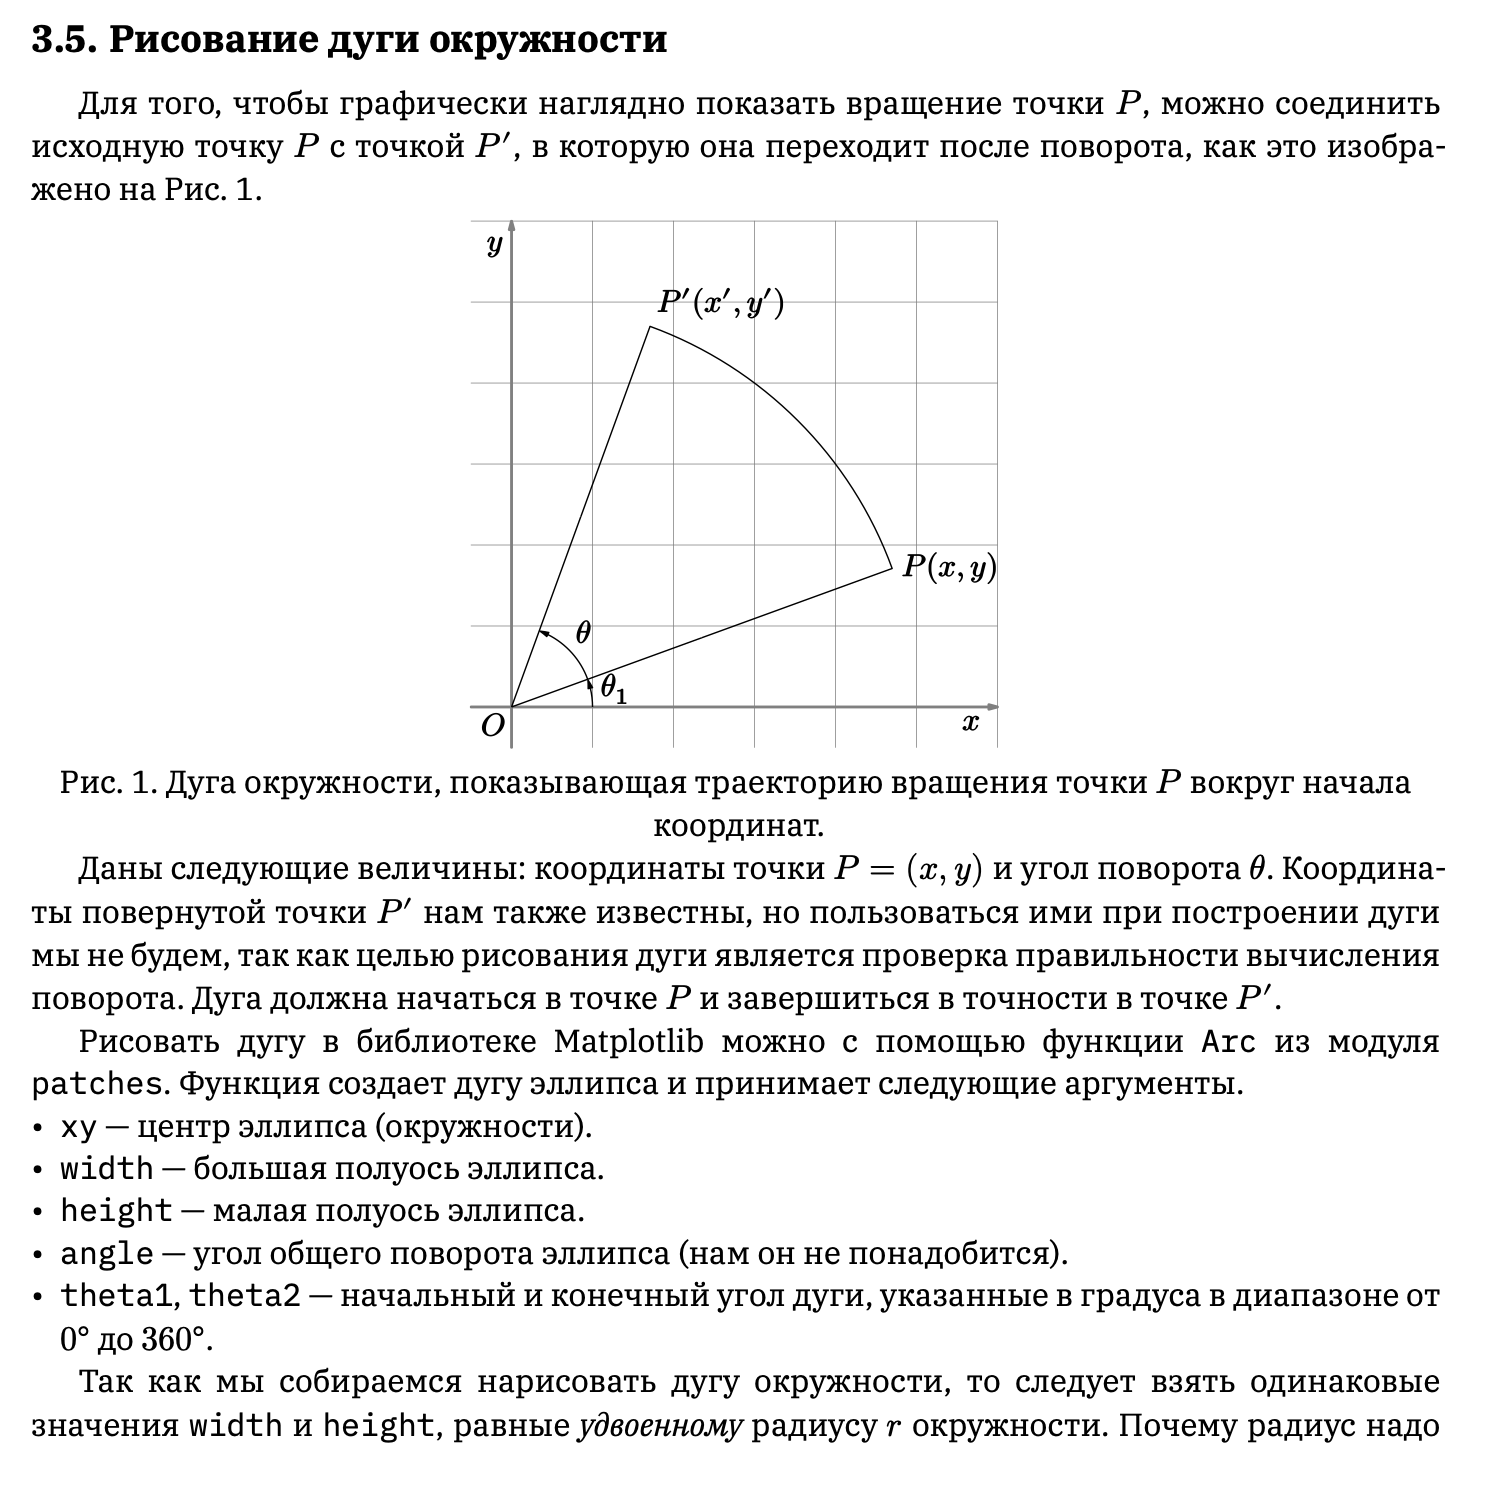

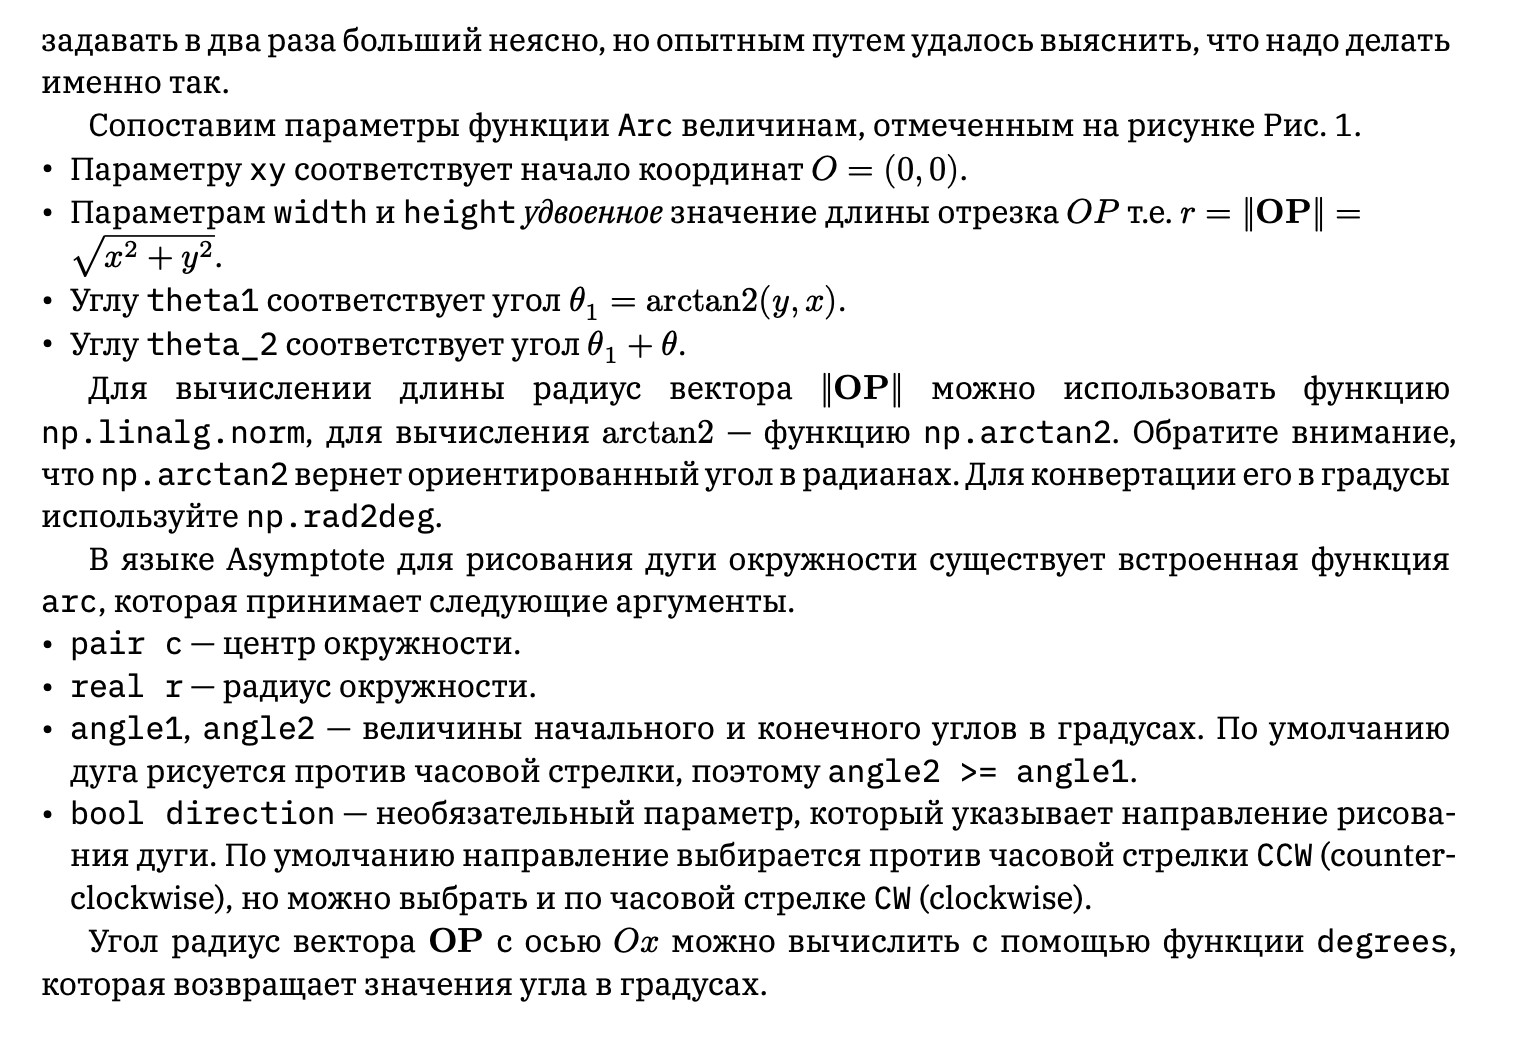

In [9]:
from matplotlib.patches import Arc

def plot_arc(x=2.0, y=1.0, theta=60.0):
    # 1. Исходная точка P
    P = np.array([x, y])
    # 2. Радиус-вектор (длина OP)
    r = np.linalg.norm(P)
    # 3. Начальный угол (в радианах)
    theta1_rad = np.arctan2(y, x)
    # 4. Начальный угол (в градусах)
    theta1_deg = np.rad2deg(theta1_rad)
    # 5. Конечный угол (theta1 + theta)
    theta2_deg = theta1_deg + theta

    # 6. Построим фигуру
    fig, ax = plt.subplots(figsize=(7,7))
    # Ось и окружность
    ax.plot([0, x], [0, y], 'b-', label='Радиус-вектор OP')
    ax.plot(x, y, 'bo', label='P (начало дуги)')
    # Повернутая точка P'
    theta2_rad = np.radians(theta2_deg)
    x2 = r * np.cos(theta2_rad)
    y2 = r * np.sin(theta2_rad)
    ax.plot([0, x2], [0, y2], 'r-', label="Радиус-вектор OP'")
    ax.plot(x2, y2, 'ro', label="P' (конец дуги)")

    # 7. Дуга окружности через Arc
    arc = Arc((0, 0), width=2*r, height=2*r, angle=0, 
              theta1=theta1_deg, theta2=theta2_deg, color='green', lw=2, label='Дуга вращения')
    ax.add_patch(arc)

    # 8. Вспомогательная окружность
    circle = plt.Circle((0, 0), r, fill=False, color='gray', linestyle='--', label='Окружность')
    ax.add_patch(circle)

    # 9. Настройки графика
    ax.set_aspect('equal')
    ax.set_xlim(-r-1, r+1)
    ax.set_ylim(-r-1, r+1)
    ax.legend()
    ax.grid(True)
    plt.title(f"Дуга вращения точки P вокруг начала координат\n"
              f"Начальный угол: {theta1_deg:.1f}°, угол поворота: {theta:.1f}°")
    plt.show()

# Интерактивные ползунки
interact(
    plot_arc,
    x=FloatSlider(value=2.0, min=-5.0, max=5.0, step=0.1, description='P_x'),
    y=FloatSlider(value=1.0, min=-5.0, max=5.0, step=0.1, description='P_y'),
    theta=FloatSlider(value=60.0, min=-360.0, max=360.0, step=1.0, description='Угол поворота (°)')
)

interactive(children=(FloatSlider(value=2.0, description='P_x', max=5.0, min=-5.0), FloatSlider(value=1.0, des…

<function __main__.plot_arc(x=2.0, y=1.0, theta=60.0)>